# 01 · Data exploration — understanding the AUV hull dataset

**Goal of this notebook:** *look* at the data before building more models. We want to understand what the hulls are,
what ranges they cover, and where (and why) prediction models fail.

**The dataset** comes from Vardhan et al. (2023). Someone designed 3,021 torpedo-shaped underwater-vehicle hulls,
ran a CFD (computational fluid dynamics) simulation on each one, and recorded the **drag force** — how hard the water
pushes back when the hull moves forward at 2 m/s.

**Sections** (we do them one at a time):
1. **The design space** ← *we are here*
2. Hull gallery — drawing the shapes
3. Physics view — friction vs shape effects
4. Error maps — where each model fails
5. The one CFD case we have
6. Data quality — duplicates, outliers, noise

> **How to use this notebook:** run each cell in order with **Shift + Enter**. Read the text above each cell first —
> it explains what the code does and what to look for in the result.

---
## Section 1 · The design space

### 1.1 What describes a hull?
Each hull is a **Myring hull**: a rounded nose, a straight cylinder in the middle, and a tapering tail.
Six numbers fully describe its shape:

| Symbol | Meaning | Unit |
|---|---|---|
| `a` | nose length | mm |
| `b` | length of the straight middle part | mm |
| `c` | tail length | mm |
| `d` | diameter (thickest width of the hull) | mm |
| `n` | nose "fullness" — small *n* = pointed nose, large *n* = blunt, rounded nose | no unit |
| `θ` (theta) | tail angle at the very end — large θ = abrupt, steep tail | degrees |

And one result per hull:

| Symbol | Meaning | Unit |
|---|---|---|
| `D` | drag force from the CFD simulation | newtons (N) |

### 1.2 Load the data
The data is two plain text files, one row per hull, seven numbers per row (`a b c d n θ D`).
- **train** (2,400 hulls): the examples models are allowed to *learn* from.
- **test** (621 hulls): kept aside to *check* models fairly — like an exam they have never seen.

In [1]:
# numpy: the standard Python library for working with arrays (tables) of numbers
import numpy as np

# Where the original authors' data lives (a read-only copy in our project folder)
DATA = '../reference/UUV-design-optimization/'
train = np.loadtxt(DATA + 'cad_cfd_pipeline_surrogate_data_generation/surrogate_data/train_2400.txt')
test  = np.loadtxt(DATA + 'uuv_optim/data/surrogate/test_data.txt')

# .shape tells us (number of rows, number of columns)
print('train:', train.shape, '  test:', test.shape)

# Show the first 3 hulls of the training set so we can see what a row looks like
print('\n   a(mm)   b(mm)   c(mm)   d(mm)    n     θ(°)   D(N)')
for row in train[:3]:
    print('  '.join(f'{v:6.1f}' for v in row))

train: (2400, 7)   test: (621, 7)

   a(mm)   b(mm)   c(mm)   d(mm)    n     θ(°)   D(N)
 253.2   561.5   292.8   107.5     3.1    49.3     3.8
 243.0   853.9   386.5   141.0     3.6    35.4     5.4
 304.9   472.5   385.0   167.8     3.9    14.2     5.1


### 1.3 Give the columns names and compute a few useful extra quantities
Working with `train[:, 3]` ("column 3 of train") is hard to read, so we give each column a name.

We also compute two **derived** quantities that engineers care about:
- **Total length** `L = a + b + c`
- **Fineness ratio** `L/d` = length ÷ diameter. It says how *slender* a hull is:
  - **L/d ≈ 5** → short and fat (like a rugby ball) — water struggles to flow smoothly around the back
  - **L/d ≈ 8–10** → typical real AUVs (e.g. the REMUS-100)
  - **L/d ≈ 20+** → very long and thin (like a pencil)

In [2]:
def columns(data):
    """Split a data table into named columns and add derived quantities. Returns a dictionary."""
    a, b, c, d, n, theta, D = data.T          # .T = transpose: turn the 7 columns into 7 separate arrays
    L = a + b + c                              # total length (mm)
    return dict(a=a, b=b, c=c, d=d, n=n, theta=theta, D=D, L=L, Ld=L / d)

tr = columns(train)
te = columns(test)

# Example: the fineness ratio of the first 5 training hulls
print('L/d of the first 5 training hulls:', np.round(tr['Ld'][:5], 1))

L/d of the first 5 training hulls: [10.3 10.5  6.9 14.2 11.8]


### 1.4 What ranges do the numbers cover?
For each quantity we print the **minimum**, **median** (the middle value: half the hulls are below it) and
**maximum**, for both train and test. If the two sets cover similar ranges, the test is a fair check of the same
"design space".

In [3]:
names = {'a': 'nose length a (mm)', 'b': 'middle length b (mm)', 'c': 'tail length c (mm)',
         'd': 'diameter d (mm)', 'n': 'nose shape n', 'theta': 'tail angle θ (°)',
         'L': 'total length L (mm)', 'Ld': 'fineness L/d', 'D': 'drag D (N)'}

print(f'{"quantity":24s} | {"train: min  median   max":>27s} | {"test: min  median   max":>26s}')
print('-' * 84)
for key, label in names.items():
    t, s = tr[key], te[key]
    print(f'{label:24s} | {t.min():8.1f} {np.median(t):8.1f} {t.max():8.1f} | '
          f'{s.min():8.1f} {np.median(s):8.1f} {s.max():8.1f}')

quantity                 |    train: min  median   max |    test: min  median   max
------------------------------------------------------------------------------------
nose length a (mm)       |     53.2    238.7    584.0 |     53.5    250.3    596.8
middle length b (mm)     |     16.4    982.7   1805.6 |      1.4    982.9   1827.2
tail length c (mm)       |     53.3    240.4    592.5 |     54.6    241.5    585.4
diameter d (mm)          |     50.0    130.5    199.9 |     50.4    134.2    199.6
nose shape n             |      1.0      3.0      5.0 |      1.0      3.2      5.0
tail angle θ (°)         |      1.0     25.8     50.0 |      1.1     24.3     49.9
total length L (mm)      |   1001.2   1490.9   1999.6 |   1001.4   1512.1   1999.7
fineness L/d             |      5.1     11.6     38.9 |      5.1     11.4     37.7
drag D (N)               |      1.4      4.9     15.9 |      1.5      5.0     21.2


### 1.5 Histograms: how are the hulls spread out?
A **histogram** splits a range into bins and counts how many hulls fall in each bin.
- **Blue** = training hulls, **orange** = test hulls (drawn semi-transparent so you can see both).
- `density=True` scales both to the same height, so we compare *shapes*, not totals (train has 4× more hulls).

**What to look for:** are some values rare? A model can only learn well where it has seen many examples.

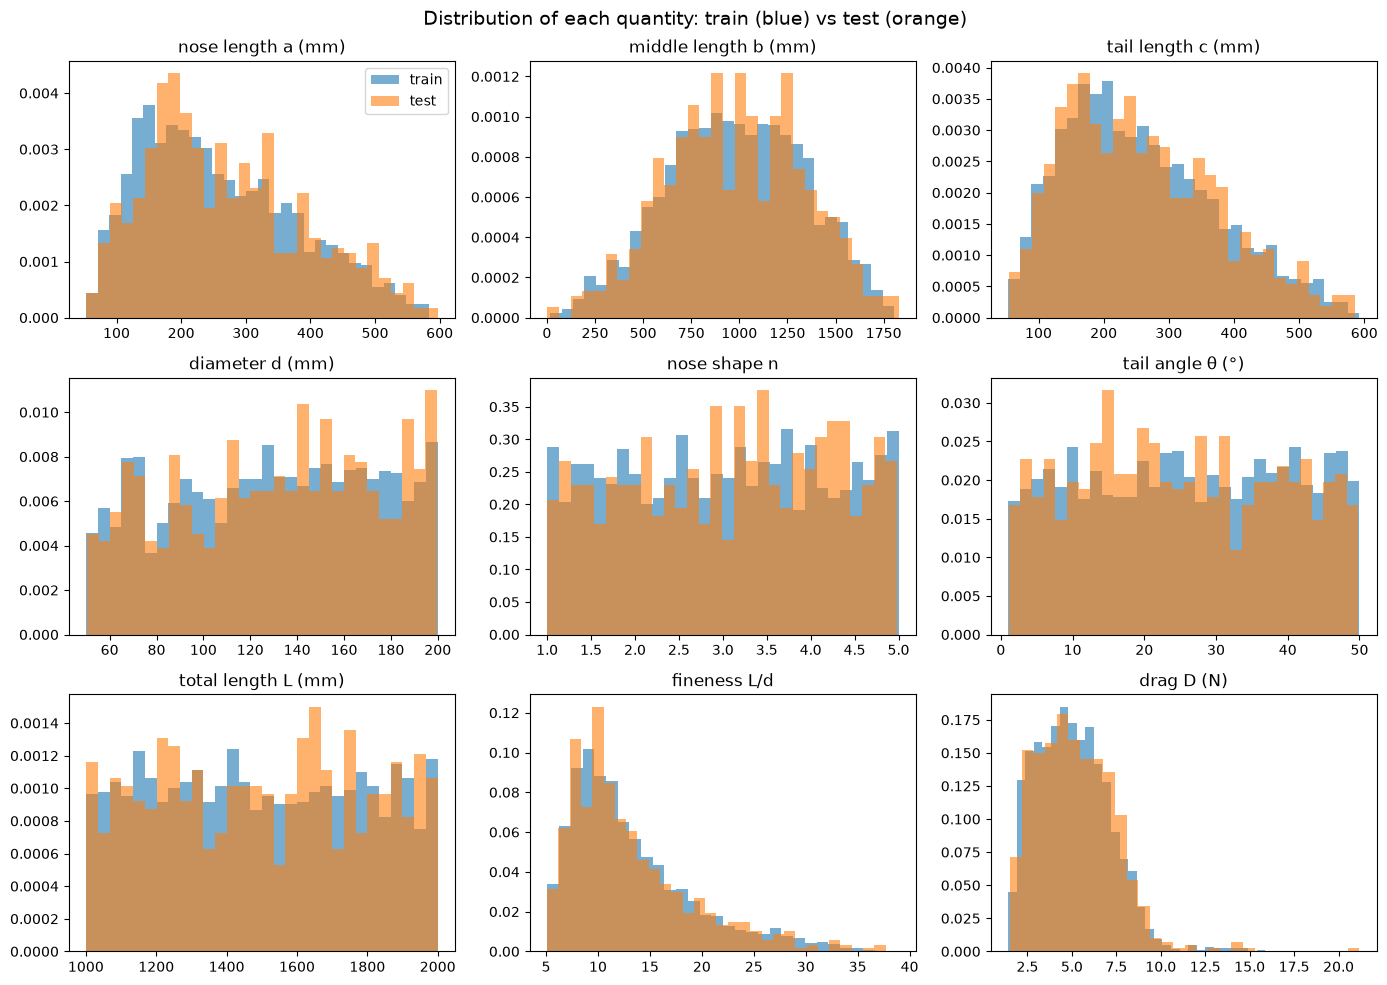

In [4]:
# matplotlib: the standard Python plotting library
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(14, 10))          # a 3 x 3 grid of small plots
for ax, (key, label) in zip(axes.ravel(), names.items()):
    ax.hist(tr[key], bins=30, alpha=0.6, density=True, label='train')
    ax.hist(te[key], bins=30, alpha=0.6, density=True, label='test')
    ax.set_title(label)
axes[0, 0].legend()
plt.suptitle('Distribution of each quantity: train (blue) vs test (orange)', fontsize=14)
plt.tight_layout()
plt.show()

### 1.6 The key question: how many *fat* hulls are there?
In the M0 analysis we found that **every model fails on fat hulls (L/d < 7)**. One simple explanation would be:
*there are just very few fat hulls to learn from.* Let's count them.

In [5]:
for label, data in [('train', tr), ('test', te)]:
    fat = data['Ld'] < 7
    print(f'{label:5s}: {fat.sum():4d} fat hulls (L/d < 7) out of {len(fat)}  →  {100 * fat.mean():.1f}%')

# How different is drag for fat hulls? Compare the median drag of fat vs slender hulls.
fat = tr['Ld'] < 7
print(f'\nMedian drag, fat hulls    : {np.median(tr["D"][fat]):.2f} N')
print(f'Median drag, slender hulls: {np.median(tr["D"][~fat]):.2f} N      (~ means "not")')

train:  217 fat hulls (L/d < 7) out of 2400  →  9.0%
test :   50 fat hulls (L/d < 7) out of 621  →  8.1%

Median drag, fat hulls    : 6.18 N
Median drag, slender hulls: 4.68 N      (~ means "not")


### 1.7 A 2D map of the design space
Histograms show one quantity at a time. A **scatter plot** of two quantities shows *combinations*.
Here: **fineness ratio (L/d)** against **diameter (d)**, each dot one hull, coloured by its drag.
The dashed line marks L/d = 7, the edge of the "fat hull" zone.

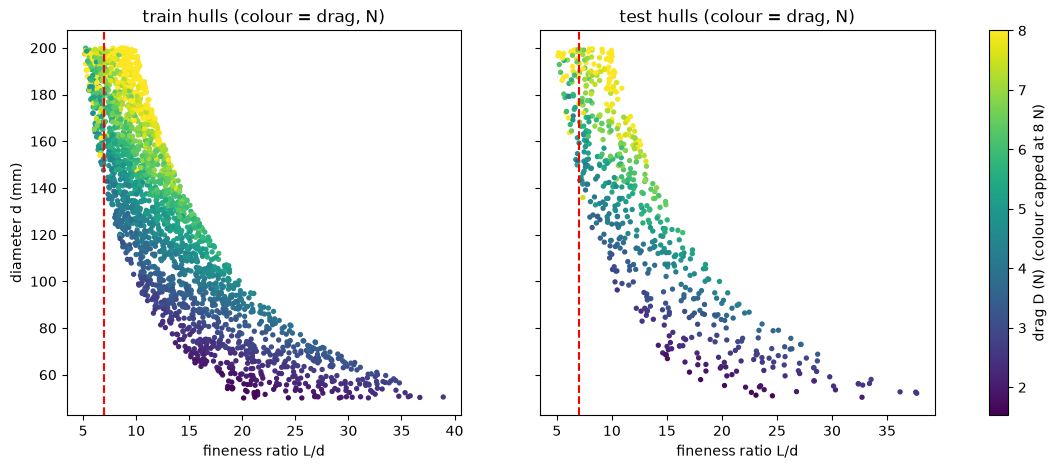

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for a_, (label, data) in zip(ax, [('train', tr), ('test', te)]):
    sc = a_.scatter(data['Ld'], data['d'], c=data['D'], s=8, cmap='viridis', vmax=8)
    a_.axvline(7, ls='--', c='red')                       # the fat-hull boundary
    a_.set(xlabel='fineness ratio L/d', title=f'{label} hulls (colour = drag, N)')
ax[0].set_ylabel('diameter d (mm)')
plt.colorbar(sc, ax=ax, label='drag D (N)  (colour capped at 8 N)')
plt.show()

### ✍️ Your turn — answer these from the outputs above (write your answers in a new Markdown cell below)
1. Do the train and test sets cover the **same ranges**? Any quantity where they differ?
2. What **percentage** of training hulls are fat (L/d < 7)? Is that *a lot* or *a little* for a model to learn from?
3. In the 2D map, **where** are the fat hulls — at large or small diameter? Why does that make geometric sense?
4. Which quantity has the most **uneven** (skewed) histogram? What could that mean for learning?

*When you are done, tell Claude your answers — then we move to Section 2 (drawing the hulls).*

SyntaxError: unmatched ')' (3693085361.py, line 2)